# 10 — Seleção temporal de modelo e margem

Este notebook simula a decisão cronológica que poderia ser tomada na prática: usa o desempenho já conhecido dos anos anteriores para escolher um par **modelo + política de margem** e avalia esse par no ano seguinte. Faz dois cortes: 2023 → 2024 e 2023–2024 → 2025.

Para cada razão hipotética de penalidade falta:sobra (1:1, 2:1, 3:1, 5:1), escolhe-se o candidato com menor perda média no período de seleção. Empates são resolvidos por menor MAE do plano e depois menor WAPE. As reservas entram somente como baseline de comparação no ano futuro; não participam da seleção do modelo.

As previsões base vêm da validação temporal walk-forward anterior. O notebook não refaz o treino dos modelos; avalia se a seleção entre previsões históricas teria escolhido uma opção que se comporta bem no período seguinte. Excesso e falta são diferenças potenciais de plano versus consumo, não desperdício nem atendimento observados. Os pesos são cenários hipotéticos, sem custos locais medidos.

In [1]:
from pathlib import Path
import os
import tempfile
import numpy as np
import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "mplconfig_novo_experimento"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd()
roots = [cwd, cwd.parent, cwd / "NOVO_EXPERIMENTO"]
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não localizei a raiz F:/PRODUTO_MESTRADO.")
LINE_ID = "reservas_consumo_cardapio_calendario_clima"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
FEATURES_DIR = ROOT / "data" / "experimentos" / LINE_ID / "features"
assert ROOT is not None, f"Não localizei a raiz NOVO_EXPERIMENTO a partir de {cwd}."
SOURCE = LINE_RESULTS / "09_margens_vs_reservas" / "previsoes_decisao_pareadas.csv"
OUT = LINE_RESULTS / "10_selecao_temporal_modelo_margem"
OUT.mkdir(parents=True, exist_ok=True)
assert SOURCE.exists(), f"Fonte do Notebook 09 ausente: {SOURCE}"

data = pd.read_csv(SOURCE, encoding="utf-8-sig", parse_dates=["data"])
data["origem"] = pd.to_datetime(data["origem"], errors="raise")
assert not data.duplicated(["metodo", "politica_margem", "data"]).any()
assert set(data["ano"].unique()) == {2023, 2024, 2025}
assert (data["origem"] < data["data"]).all(), "Há previsão com origem não anterior ao alvo."
reserve_name = "Baseline_Reservas::total_reservas_observado"
reservas = data[data["metodo"] == reserve_name].copy()
models = data[data["metodo"] != reserve_name].copy()
assert models["metodo"].nunique() > 0
assert models["politica_margem"].nunique() == 8
assert models.groupby(["metodo", "politica_margem"])["data"].nunique().eq(models["data"].nunique()).all()
print(f"Fonte: {len(data):,} linhas; {models.metodo.nunique()} métodos; {models.politica_margem.nunique()} políticas; {models.data.nunique()} datas comuns entre 2023–2025.")
print("Cortes futuros: treino/seleção 2023 → teste 2024; treino/seleção 2023–2024 → teste 2025.")


Fonte: 203,190 linhas; 65 métodos; 8 políticas; 390 datas comuns entre 2023–2025.
Cortes futuros: treino/seleção 2023 → teste 2024; treino/seleção 2023–2024 → teste 2025.


In [2]:
# A seleção é feita apenas com os anos anteriores a cada teste.
ratios = [1, 2, 3, 5]
cuts = {2024: [2023], 2025: [2023, 2024]}
selection_rows = []
test_rows = []
ranking_rows = []

def score(frame, ratio):
    target_sum = frame["consumo_real"].sum()
    return {
        "n_datas": int(frame["data"].nunique()),
        "MAE_plano": float(frame["erro_plano_abs"].mean()),
        "WAPE_plano_pct": float(frame["erro_plano_abs"].sum() / target_sum * 100) if target_sum else np.nan,
        "excesso_medio_dia": float(frame["excesso_potencial"].mean()),
        "falta_media_dia": float(frame["falta_potencial"].mean()),
        "excesso_total": float(frame["excesso_potencial"].sum()),
        "falta_total": float(frame["falta_potencial"].sum()),
        "dias_com_cobertura_pct": float(frame["cobriu_dia"].mean() * 100),
        "perda_relativa_media_dia": float((frame["excesso_potencial"] + ratio * frame["falta_potencial"]).mean()),
    }

for test_year, train_years in cuts.items():
    train = models[models["ano"].isin(train_years)].copy()
    future = models[models["ano"] == test_year].copy()
    reserve_future = reservas[reservas["ano"] == test_year].copy()
    assert set(train["ano"].unique()) == set(train_years)
    assert future["data"].min() > train["data"].max(), "Treino e teste não estão em ordem temporal."
    assert future["data"].nunique() == reserve_future["data"].nunique()
    assert set(future["data"]) == set(reserve_future["data"])
    for ratio in ratios:
        train = train.assign(perda=(train["excesso_potencial"] + ratio * train["falta_potencial"]))
        ranking = train.groupby(["metodo", "politica_margem"], as_index=False).agg(
            perda_media_treino=("perda", "mean"),
            MAE_treino=("erro_plano_abs", "mean"),
            erro_abs_treino=("erro_plano_abs", "sum"),
            consumo_treino=("consumo_real", "sum"),
            n_datas_treino=("data", "nunique"),
        )
        ranking["WAPE_treino_pct"] = ranking["erro_abs_treino"] / ranking["consumo_treino"] * 100
        ranking = ranking.sort_values(["perda_media_treino", "MAE_treino", "WAPE_treino_pct", "metodo", "politica_margem"])
        winner = ranking.iloc[0]
        top = ranking.head(10).copy()
        top["ano_teste"] = test_year
        top["anos_selecao"] = "+".join(map(str, train_years))
        top["razao_falta_sobra"] = ratio
        ranking_rows.append(top)

        selected_test = future[(future["metodo"] == winner["metodo"]) & (future["politica_margem"] == winner["politica_margem"])].copy()
        reserve_test = reserve_future.copy()
        assert selected_test["data"].nunique() == reserve_test["data"].nunique()
        selected_scores = score(selected_test, ratio)
        reserve_scores = score(reserve_test, ratio)
        selection_rows.append({
            "ano_teste": test_year,
            "anos_selecao": "+".join(map(str, train_years)),
            "razao_falta_sobra": ratio,
            "metodo_selecionado": winner["metodo"],
            "politica_selecionada": winner["politica_margem"],
            "perda_treino_media_dia": float(winner["perda_media_treino"]),
            "n_datas_selecao": int(winner["n_datas_treino"]),
            **{f"selecionado_{k}": v for k, v in selected_scores.items()},
            **{f"reservas_{k}": v for k, v in reserve_scores.items()},
            "delta_perda_vs_reservas": selected_scores["perda_relativa_media_dia"] - reserve_scores["perda_relativa_media_dia"],
            "reducao_perda_vs_reservas_pct": (1 - selected_scores["perda_relativa_media_dia"] / reserve_scores["perda_relativa_media_dia"]) * 100,
        })
        for tag, frame in [("selecionado", selected_test), ("reservas", reserve_test)]:
            keep = frame[["data", "ano", "metodo", "politica_margem", "quantidade_planejada", "consumo_real", "excesso_potencial", "falta_potencial", "erro_plano_abs", "cobriu_dia"]].copy()
            keep["ano_teste"] = test_year
            keep["anos_selecao"] = "+".join(map(str, train_years))
            keep["razao_falta_sobra"] = ratio
            keep["regra_comparada"] = tag
            if tag == "selecionado":
                keep["metodo_escolhido"] = winner["metodo"]
                keep["politica_escolhida"] = winner["politica_margem"]
            else:
                keep["metodo_escolhido"] = winner["metodo"]
                keep["politica_escolhida"] = winner["politica_margem"]
            test_rows.append(keep)

selection = pd.DataFrame(selection_rows)
selection.to_csv(OUT / "resultado_selecao_temporal.csv", index=False, encoding="utf-8-sig")
pd.concat(ranking_rows, ignore_index=True).to_csv(OUT / "top10_selecao_historica.csv", index=False, encoding="utf-8-sig")
test_detail = pd.concat(test_rows, ignore_index=True)
test_detail.to_csv(OUT / "previsoes_holdout_pareadas.csv", index=False, encoding="utf-8-sig")
display(selection[[
    "ano_teste", "anos_selecao", "razao_falta_sobra", "metodo_selecionado", "politica_selecionada",
    "perda_treino_media_dia", "selecionado_perda_relativa_media_dia", "reservas_perda_relativa_media_dia",
    "selecionado_MAE_plano", "reservas_MAE_plano", "selecionado_WAPE_plano_pct", "reservas_WAPE_plano_pct",
    "reducao_perda_vs_reservas_pct", "selecionado_excesso_medio_dia", "selecionado_falta_media_dia",
    "selecionado_dias_com_cobertura_pct",
]].round(2))
print("Nenhuma observação do ano de teste participou da seleção do candidato nesse corte.")


,ano_teste,anos_selecao,razao_falta_sobra,metodo_selecionado,politica_selecionada,perda_treino_media_dia,selecionado_perda_relativa_media_dia,reservas_perda_relativa_media_dia,selecionado_MAE_plano,reservas_MAE_plano,selecionado_WAPE_plano_pct,reservas_WAPE_plano_pct,reducao_perda_vs_reservas_pct,selecionado_excesso_medio_dia,selecionado_falta_media_dia,selecionado_dias_com_cobertura_pct
0,2024,2023,1,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_5,16.82,24.66,39.82,24.66,39.82,14.75,23.81,38.06,11.93,12.73,51.64
1,2024,2023,2,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_10,20.34,35.53,76.90,25.09,39.82,15.00,23.81,53.79,14.65,10.44,57.38
2,2024,2023,3,Atual_mais_reservas::Ensemble_top5_validacao_m...,margem_fixa_10,22.42,45.98,113.98,25.09,39.82,15.00,23.81,59.66,14.65,10.44,57.38
3,2024,2023,5,Atual_mais_reservas::CatBoost_native,margem_fixa_15,25.86,80.19,188.15,27.53,39.82,16.46,23.81,57.38,14.37,13.16,55.74
4,2025,2023+2024,1,Atual_mais_reservas_clima::BayesianRidge,margem_fixa_0,20.08,22.30,28.79,22.30,28.79,16.12,20.80,22.52,13.86,8.45,54.84
5,2025,2023+2024,2,Atual_mais_reservas_clima::BayesianRidge,margem_fixa_10,27.29,29.45,53.28,24.77,28.79,17.90,20.80,44.73,20.09,4.68,72.26
6,2025,2023+2024,3,Atual_mais_reservas_clima::BayesianRidge,margem_fixa_15,32.12,34.12,77.77,27.26,28.79,19.70,20.80,56.13,23.84,3.43,80.00
7,2025,2023+2024,5,Atual_mais_reservas_clima::BayesianRidge,margem_fixa_20,38.92,40.78,126.75,30.54,28.79,22.07,20.80,67.83,27.97,2.56,85.81


Nenhuma observação do ano de teste participou da seleção do candidato nesse corte.


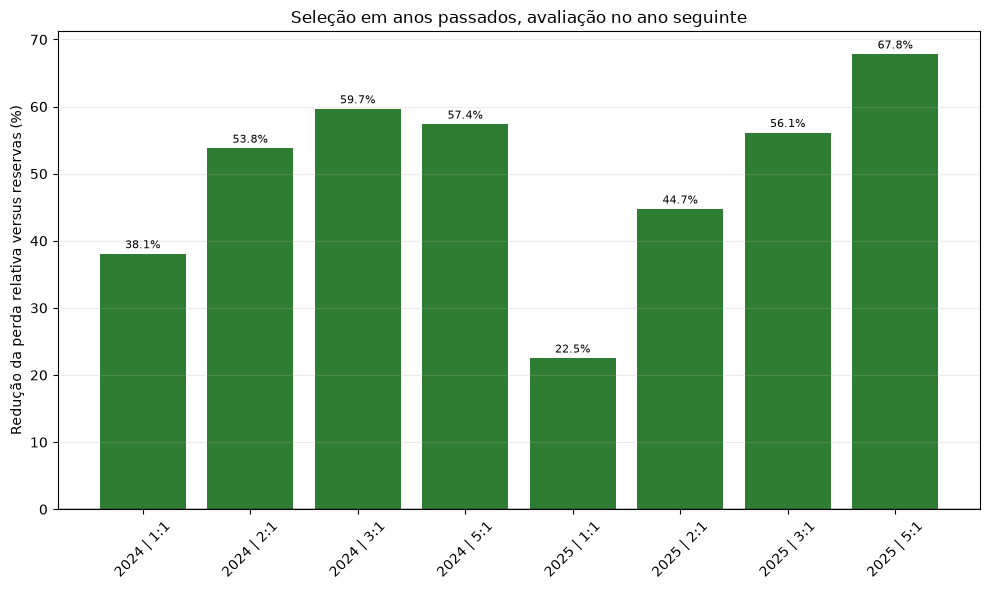

Gráfico salvo em F:\PRODUTO_MESTRADO\resultados\linhas\reservas_consumo_cardapio_calendario_clima\10_selecao_temporal_modelo_margem\selecao_temporal_vs_reservas.png.
Relatório salvo em F:\PRODUTO_MESTRADO\resultados\linhas\reservas_consumo_cardapio_calendario_clima\10_selecao_temporal_modelo_margem\RELATORIO_NOTEBOOK_10.md.


In [3]:
# Comparar perda relativa do candidato escolhido com reservas em cada ano/razão.
fig, ax = plt.subplots(figsize=(10, 6))
plot = selection.copy()
plot["rotulo"] = plot["ano_teste"].astype(str) + " | " + plot["razao_falta_sobra"].astype(str) + ":1"
values = plot["reducao_perda_vs_reservas_pct"].to_numpy()
colors = ["#2E7D32" if v >= 0 else "#B71C1C" for v in values]
bars = ax.bar(plot["rotulo"], values, color=colors)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Redução da perda relativa versus reservas (%)")
ax.set_title("Seleção em anos passados, avaliação no ano seguinte")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=.25)
for bar, value in zip(bars, values):
    ax.annotate(f"{value:.1f}%", (bar.get_x()+bar.get_width()/2, value),
                xytext=(0, 4 if value >= 0 else -13), textcoords="offset points", ha="center", fontsize=8)
fig.tight_layout()
chart = OUT / "selecao_temporal_vs_reservas.png"
fig.savefig(chart, dpi=170, bbox_inches="tight")
plt.show()
print(f"Gráfico salvo em {chart}.")

# Síntese reproduzível, sem chamar perda relativa de custo real.
pt = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")
lines = [
    "# Relatório — seleção temporal de modelo e margem",
    "",
    "A seleção de cada par modelo+margem usou apenas os anos anteriores ao ano de teste. As reservas foram mantidas como baseline e não participaram da seleção dos candidatos.",
    "",
    "| Seleção → teste | Peso | Método escolhido | Margem | MAE plano (sel./res.) | WAPE % (sel./res.) | Perda teste (sel./res.) | Redução perda | Excesso/dia | Falta/dia | Cobertura |",
    "|---|---:|---|---|---:|---:|---:|---:|---:|---:|---:|",
]
for r in selection.itertuples(index=False):
    lines.append(
        f"| {r.anos_selecao} → {r.ano_teste} | {r.razao_falta_sobra}:1 | {r.metodo_selecionado} | {r.politica_selecionada} | {pt(r.selecionado_MAE_plano)} / {pt(r.reservas_MAE_plano)} | {pt(r.selecionado_WAPE_plano_pct)} / {pt(r.reservas_WAPE_plano_pct)} | {pt(r.selecionado_perda_relativa_media_dia)} / {pt(r.reservas_perda_relativa_media_dia)} | {pt(r.reducao_perda_vs_reservas_pct, 1)}% | {pt(r.selecionado_excesso_medio_dia)} | {pt(r.selecionado_falta_media_dia)} | {pt(r.selecionado_dias_com_cobertura_pct, 1)}% |"
    )
lines += [
    "",
    "## Interpretação e limites",
    "",
    "Esse corte temporal reduz o viés de escolher e pontuar na mesma janela. A família do modelo e a política de margem ficam escolhidas com anos anteriores; as previsões de cada ano de teste vêm dos folds walk-forward existentes. Em cada origem semanal, o modelo pode usar consumo que já foi observado antes daquela origem, inclusive de semanas anteriores do próprio ano de teste. Este experimento representa seleção congelada com atualização sequencial do aprendizado, não um modelo imutável treinado uma única vez no primeiro dia do ano.",
    "",
    "Ainda assim, são apenas dois anos de teste e os pesos falta:sobra são hipóteses, não custos observados. A comparação é retrospectiva e este notebook não retreina nem ajusta os modelos.",
    "",
    "Os valores de excesso e falta são desvios potenciais entre quantidade planejada e consumo. Eles não indicam quanto foi produzido, descartado ou quantos estudantes deixaram de ser atendidos. Para essas conclusões são necessários registros reais de produção, sobras e refeições não atendidas pareados por data.",
    "",
    "A seleção pode mudar entre os cortes e entre os pesos. Isso é esperado: a decisão depende do período observado e da consequência relativa atribuída à falta. O artefato deve apresentar essa sensibilidade para apoiar a gestão, sem impor uma margem universal.",
    "",
    "Consulte `resultado_selecao_temporal.csv`, `top10_selecao_historica.csv` e `previsoes_holdout_pareadas.csv`.",
]
(OUT / "RELATORIO_NOTEBOOK_10.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"Relatório salvo em {OUT / 'RELATORIO_NOTEBOOK_10.md'}.")


## Auditorias e limites

- O ano de teste não participa da seleção do par modelo+margem.
- Os alvos usados na seleção pertencem somente a anos anteriores; o pareamento e as reservas são idênticos no ano de teste.
- O corte de 2024 tem um único ano de seleção e poucos registros de 2023; interprete-o como teste inicial.
- Pesos de falta:sobra são cenários de sensibilidade e não custos institucionais observados.
- As previsões dos modelos são de validação walk-forward preexistente. Este estudo avalia a seleção posterior dos candidatos, não substitui uma validação prospectiva ou operacional.
- Registros de produção, sobras e refeições não atendidas são necessários para medir desperdício e serviço reais; sem eles, os resultados permanecem potenciais/descritivos.